# Assignment 2, Part A: Count based representations
**Member 1:** Maham Iqbal (L1F23BSCS0411)
**Corpus:** cleaned tweets from Phase 1 (`data/processed/cleaned_dataset.csv`), loaded through `src/corpus.py`

| Task | What we do |
|---|---|
| A1 | Bag of Words matrix, its shape and sparsity |
| A2 | TF-IDF matrix, words with high weight and common words pushed toward zero |
| A3 | Unigrams, bigrams and trigrams: how the number of features grows and what happens to sparsity |
| A4 | Hand worked TF-IDF weight and bigram on 4 tiny documents, checked against scikit-learn |

> Run everything with *Kernel → Restart Kernel and Run All Cells*, then take screenshots for the report.

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name in ("notebooks", "notebook"):
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import corpus
import count_representations as cr
import hand_worked_a4 as a4

pd.set_option("display.max_colwidth", 120)
%matplotlib inline

## The corpus
All parts of Assignment 2 use `corpus.load_corpus()` so the comparisons are fair. It removes the 155 repeated tweet IDs and the tweets that became empty after cleaning. The text is **not** cleaned again.

In [ ]:
df = corpus.load_corpus()
docs = corpus.documents(df)
corpus.corpus_summary(df)

{'rows_in_cleaned_file': 14640,
 'repeated_tweet_ids_removed': 155,
 'empty_after_cleaning_removed': 56,
 'documents_used': 14429,
 'total_tokens': 118649,
 'vocabulary_size': 8961,
 'avg_tokens_per_doc': 8.22,
 'labels': {'negative': 9067, 'neutral': 3029, 'positive': 2333}}

In [ ]:
df[["text", "clean_text", "airline_sentiment"]].head()

,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,say,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus add commercial experience tacky,positive
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,not today mean need trip,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl...",really aggressive blast obnoxious entertainment guest face little recourse,negative
4,@VirginAmerica and it's a really big bad thing about it,really big bad thing,negative


**Why `token_pattern=r"(?u)\S+"`?** `clean_text` is already tokenized by our Phase 1 pipeline (tokens joined by spaces). scikit-learn's default pattern `(?u)\b\w\w+\b` would silently drop one letter tokens like *u* and digits. Splitting on spaces keeps exactly our tokens.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
example = "u not happy flight 2nd time"
print("default pattern :", CountVectorizer().build_analyzer()(example))
print("our pattern     :", CountVectorizer(token_pattern=corpus.TOKEN_PATTERN).build_analyzer()(example))

default pattern : ['not', 'happy', 'flight', '2nd', 'time']
our pattern     : ['u', 'not', 'happy', 'flight', '2nd', 'time']


## A1. Bag of Words

In [ ]:
bow_vec, X_bow = cr.build_bow(docs)
a1 = cr.sparsity_stats(X_bow)
a1

{'n_documents': 14429,
 'n_features': 8961,
 'total_cells': 129298269,
 'non_zero_cells': 113729,
 'zero_cells': 129184540,
 'sparsity_percent': 99.912,
 'avg_non_zero_per_doc': 7.88,
 'sparse_matrix_MB': 1.42,
 'dense_matrix_MB_if_float64': 1034.4}

In [ ]:
print(f"Shape: {X_bow.shape[0]:,} tweets x {X_bow.shape[1]:,} words")
print(f"Sparsity: {a1['sparsity_percent']}% of the cells are zero")
print(f"On average a tweet uses only {a1['avg_non_zero_per_doc']} of the {X_bow.shape[1]:,} columns")
print(f"Sparse storage: {a1['sparse_matrix_MB']} MB vs {a1['dense_matrix_MB_if_float64']} MB if stored as a full table")

Shape: 14,429 tweets x 8,961 words
Sparsity: 99.912% of the cells are zero
On average a tweet uses only 7.88 of the 8,961 columns
Sparse storage: 1.42 MB vs 1034.4 MB if stored as a full table


In [ ]:
# What one row of the matrix looks like (only the non zero cells)
print(docs[1])
cr.show_bow_row(bow_vec, X_bow, docs, 1)

plus add commercial experience tacky


,term,count
0,plus,1
1,add,1
2,commercial,1
3,experience,1
4,tacky,1


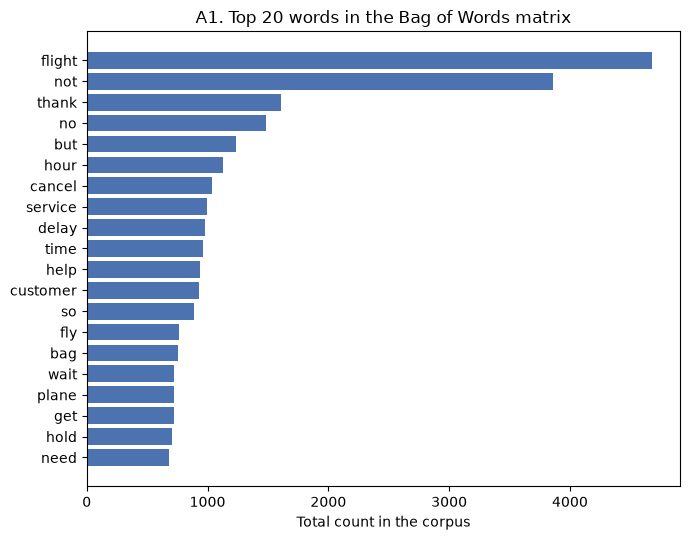

In [ ]:
freq = cr.term_frequencies(bow_vec, X_bow)
cr.plot_top_words(freq, 20, cr.FIG_DIR / "part_a_top_words.png")
plt.show()

## A2. TF-IDF
scikit-learn's defaults (written out in `cr.build_tfidf`):
- **tf** = how many times the word appears in the tweet
- **idf** = ln((1 + n) / (1 + df)) + 1, where n = number of tweets and df = number of tweets that contain the word
- each row is divided by its length so every tweet vector has length 1 (L2 norm)

A word that appears in many tweets gets a small idf, so its weight is pushed toward zero. A word that appears in very few tweets gets a large idf, so it gets a high weight.

In [ ]:
tfidf_vec, X_tfidf = cr.build_tfidf(docs)
print("Shape:", X_tfidf.shape, "  sparsity:", cr.sparsity_stats(X_tfidf)["sparsity_percent"], "%")
idf = cr.idf_table(tfidf_vec, freq)

Shape: (14429, 8961)   sparsity: 99.912 %


In [ ]:
print("Lowest IDF = most common words (pushed toward zero)")
idf.head(10).round(4)

Lowest IDF = most common words (pushed toward zero)


,term,idf,doc_freq,total_count
2954,flight,2.3194,3856,4677
5410,not,2.4405,3416,3861
7819,thank,3.2214,1564,1604
5326,no,3.3707,1347,1482
1144,but,3.4820,1205,1234
3747,hour,3.6054,1065,1128
1202,cancel,3.6733,995,1040
6991,service,3.7018,967,994
2037,delay,3.7473,924,983
3591,help,3.7680,905,938


In [ ]:
print("Highest IDF = rare words (biggest boost). Sample of real words:")
display(cr.rare_word_sample(idf, 10).round(4))
print((idf["idf"] == idf["idf"].max()).sum(), "words share the maximum IDF (each is in only one tweet)")

Highest IDF = rare words (biggest boost). Sample of real words:


,term,idf,doc_freq,total_count
1485,clusterfuck,9.8839,1,1
2094,designate,9.8839,1,1
2720,expen,9.8839,1,1
3483,habitrail,9.8839,1,1
4181,james,9.8839,1,1
5349,nofood,9.8839,1,1
6548,reppe,9.8839,1,1
6941,secondly,9.8839,1,1
8320,unpleased,9.8839,1,1
8323,unprepared,9.8839,1,1


4591 words share the maximum IDF (each is in only one tweet)


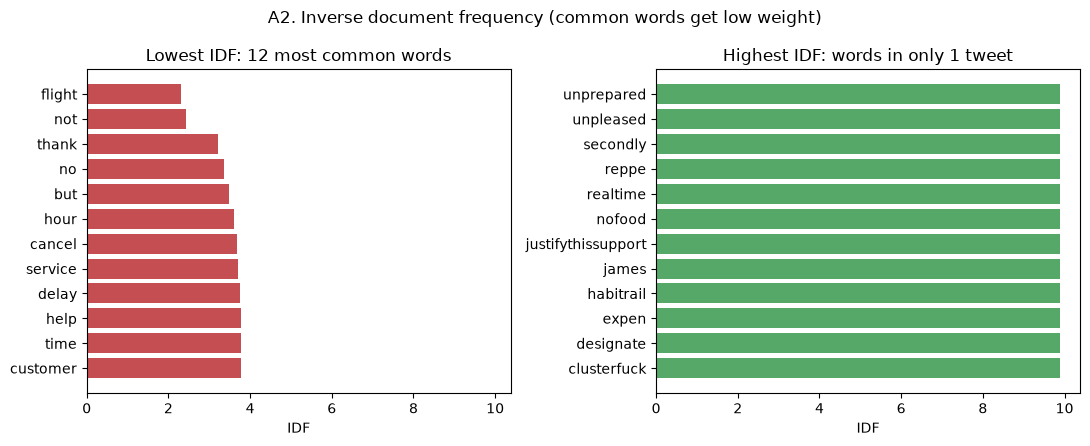

In [ ]:
cr.plot_idf(idf, 12, cr.FIG_DIR / "part_a_idf.png")
plt.show()

### A concrete example from our data

In [ ]:
row = cr.pick_example_row(df, idf)
print("tweet_id:", df.at[row, "tweet_id"], "| label:", df.at[row, "airline_sentiment"])
print("raw  :", df.at[row, "text"])
print("clean:", docs[row])
cr.tfidf_example(tfidf_vec, X_tfidf, bow_vec, X_bow, idf, row)

tweet_id: 570300767074181121 | label: negative
raw  : @VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.
it's really the only bad thing about flying VA
clean: seriously pay flight seat not playing really bad thing fly va


,term,count_in_tweet,doc_freq,idf,tfidf_weight
8,playing,1,1,9.8839,0.5261
10,va,1,9,8.2745,0.4404
4,seriously,1,80,6.1826,0.3291
3,thing,1,128,5.7173,0.3043
5,pay,1,273,4.9639,0.2642
1,really,1,291,4.9003,0.2608
7,seat,1,444,4.4790,0.2384
2,bad,1,445,4.4767,0.2383
9,fly,1,737,3.9731,0.2115
0,not,1,3416,2.4405,0.1299


Every word appears once in this tweet, so the only difference between the weights comes from the idf. *flight* and *not* appear in thousands of tweets, so they get the lowest weights. *playing* appears in this tweet only, so it gets the highest weight.

## A3. N-grams

In [ ]:
growth = cr.ngram_growth(docs)
growth.drop(columns=["ngram_range"])

,setting,features,non_zero_cells,sparsity_percent,avg_non_zero_per_doc,features_in_only_1_tweet,percent_in_only_1_tweet,features_with_min_df_2,sparsity_percent_min_df_2
0,"unigrams (1,1)",8961,113729,99.9120,7.88,4591,51.23,4370,99.8269
1,"bigrams only (2,2)",65568,103398,99.9891,7.17,54600,83.27,10968,99.9692
2,"trigrams only (3,3)",83072,89722,99.9925,6.22,79812,96.08,3260,99.9789
3,"uni + bi (1,2)",74529,217127,99.9798,15.05,59191,79.42,15338,99.9286
4,"uni + bi + tri (1,3)",157601,306849,99.9865,21.27,139003,88.20,18598,99.9375


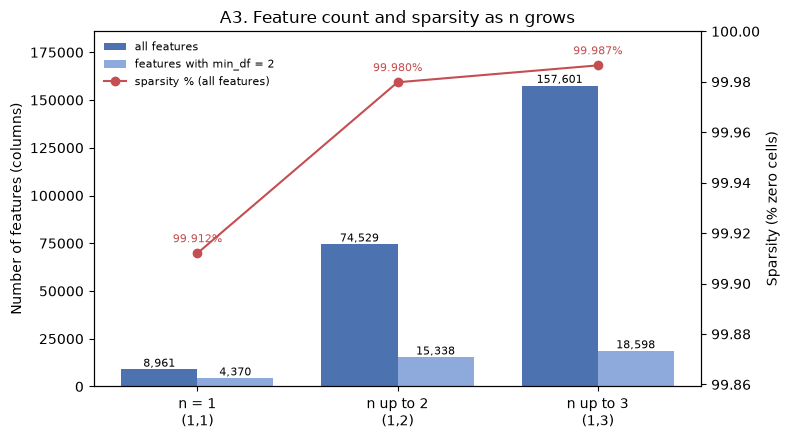

In [ ]:
cr.plot_ngram_growth(growth, cr.FIG_DIR / "part_a_ngram_growth.png")
plt.show()

In [ ]:
print("Top bigrams")
display(cr.top_ngrams(docs, 2, 15))
print("Top trigrams")
display(cr.top_ngrams(docs, 3, 15))

Top bigrams


,term,total_count,doc_freq
0,customer service,564,559
1,cancel flightle,457,447
2,cancel flight,323,313
3,flight cancel,248,246
4,late flight,246,235
5,but not,224,224
6,flight delay,172,170
7,late flightr,156,154
8,hold hour,154,154
9,fleet fleek,146,146


Top trigrams


,term,total_count,doc_freq
0,flight cancel flightle,140,140
1,cancel flightle flight,129,127
2,cancel flight flight,118,118
3,hand fold hand,102,11
4,fold hand fold,98,11
5,flight booking problem,89,86
6,face smile eye,59,48
7,face tear joy,58,26
8,rt fleet fleek,53,53
9,bad customer service,47,47


In [ ]:
# Where do "cancel flightle" and "late flightr" come from? Look at the raw tweets.
for pattern in ["Cancelled Flightled", "Late Flightr", "fleet's on fleek"]:
    m = df["text"].str.contains(pattern, case=False, regex=False)
    print(f"{pattern!r}: {m.sum()} tweets, e.g. {df.loc[m, 'text'].iloc[0]!r}\n")

'Cancelled Flightled': 491 tweets, e.g. '@VirginAmerica I like the TV and interesting video . Just disappointed in Cancelled Flightled flight when other flights went out to jfk on Saturday .'

'Late Flightr': 161 tweets, e.g. '@united See? We were told repeatedly that the pilot was Late Flight and kept getting Late Flightr.  After we boarded, there was a defibrillator issue.'

"fleet's on fleek": 144 tweets, e.g. "@CatfoodBeerGlue you'll enjoy this. \n\n“@JetBlue: Our fleet's on fleek. http://t.co/2thC9RKURT”"



## A4. Hand worked numerical (method from class)
Four short real tweets from our data. We use the rules from Lecture 7 and the class TF-IDF workbook:

| Rule | Formula |
|---|---|
| TF(t, d) | count of t in d ÷ number of words in d |
| DF(t) | number of documents that contain t |
| IDF(t) | log10(N ÷ DF(t)) |
| TF-IDF(t, d) | TF(t, d) × IDF(t) |
| Bigram probability | P(next \| previous) = count(pair) ÷ count(previous) |

We compute one TF-IDF weight and one bigram by hand and check them against the library. **The same arithmetic is done on paper and the scanned copy is attached to the report.**

In [ ]:
raw_docs, toy = a4.toy_corpus()
for name, r, d in zip(a4.DOC_NAMES, raw_docs, toy):
    print(f"{name}: {d!r:<28} raw: {r!r}")

D1: 'book flight hawaii'         raw: '@VirginAmerica when can I book my flight to Hawaii??'
D2: 'learn book flight'          raw: '@united and learn how to book flights. http://t.co/MHHS9RUpLv'
D3: 'good flight attendant'      raw: '@VirginAmerica You have the best flight attendant ever!!! http://t.co/PxdEL1nq3l'
D4: 'flight voucher'             raw: '@united where is my flight voucher?'


In [ ]:
tables = a4.class_tables(toy)
print("Word counts (and document length)")
display(tables["counts"])
print("TF = count / document length")
display(tables["tf"])

Word counts (and document length)


,attendant,book,flight,good,hawaii,learn,voucher,doc length
D1,0,1,1,0,1,0,0,3
D2,0,1,1,0,0,1,0,3
D3,1,0,1,1,0,0,0,3
D4,0,0,1,0,0,0,1,2


TF = count / document length


,attendant,book,flight,good,hawaii,learn,voucher
D1,0.000000,0.333333,0.333333,0.000000,0.333333,0.000000,0.0
D2,0.000000,0.333333,0.333333,0.000000,0.000000,0.333333,0.0
D3,0.333333,0.000000,0.333333,0.333333,0.000000,0.000000,0.0
D4,0.000000,0.000000,0.500000,0.000000,0.000000,0.000000,0.5


In [ ]:
print("DF and IDF = log10(N / DF), N = 4")
display(tables["idf"])
print("TF-IDF = TF x IDF")
display(tables["tfidf"])

DF and IDF = log10(N / DF), N = 4


,DF,N / DF,IDF = log10(N/DF)
attendant,1,4.0,0.60206
book,2,2.0,0.30103
flight,4,1.0,0.00000
good,1,4.0,0.60206
hawaii,1,4.0,0.60206
learn,1,4.0,0.60206
voucher,1,4.0,0.60206


TF-IDF = TF x IDF


,attendant,book,flight,good,hawaii,learn,voucher
D1,0.000000,0.100343,0.0,0.000000,0.200687,0.000000,0.00000
D2,0.000000,0.100343,0.0,0.000000,0.000000,0.200687,0.00000
D3,0.200687,0.000000,0.0,0.200687,0.000000,0.000000,0.00000
D4,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.30103


In [ ]:
w, steps = a4.hand_tfidf(toy, a4.TFIDF_TERM, a4.TFIDF_DOC)
print("\n".join(steps))
lib = a4.library_tfidf(toy, a4.TFIDF_TERM, a4.TFIDF_DOC)
print(f"\nLibrary: {lib:.6f}   Hand: {w:.6f}   ->", "MATCH" if abs(lib - w) < 1e-9 else "DIFFERENT")

Target: TF-IDF of 'hawaii' in D1 = 'book flight hawaii'
Rules (class method): TF = count / doc length,  IDF = log10(N / DF),  TF-IDF = TF x IDF
1. Document length of D1       = 3 words
2. Count('hawaii', D1)         = 1
3. TF('hawaii', D1)            = 1 / 3 = 0.333333
4. Number of documents N       = 4
5. DF('hawaii')                = 1 document(s)
6. N / DF                      = 4 / 1 = 4
7. IDF('hawaii')               = log10(4) = 0.602060
8. TF-IDF('hawaii', D1)        = 0.333333 x 0.602060 = 0.200687
   (compare 'book': TF = 1/3, DF = 2, IDF = log10(4/2) = 0.301030, TF-IDF = 0.100343)
   (compare 'flight': TF = 1/3, DF = 4, IDF = log10(4/4) = 0.000000, TF-IDF = 0.000000)

Library: 0.200687   Hand: 0.200687   -> MATCH


In [ ]:
c, p, steps = a4.hand_bigram(toy, a4.BIGRAM, a4.BIGRAM_FIRST)
print("\n".join(steps))
lc, lp = a4.library_bigram(toy, a4.BIGRAM, a4.BIGRAM_FIRST)
print(f"\nLibrary: count = {lc}, P = {lp:.4f}   Hand: count = {c}, P = {p:.4f}   ->", "MATCH" if (lc == c and abs(lp - p) < 1e-12) else "DIFFERENT")

Bigrams (n = 2) of each document:
  D1 'book flight hawaii': book flight · flight hawaii   ->  count('book flight') = 1
  D2 'learn book flight': learn book · book flight   ->  count('book flight') = 1
  D3 'good flight attendant': good flight · flight attendant   ->  count('book flight') = 0
  D4 'flight voucher': flight voucher   ->  count('book flight') = 0
count(book flight)   = 2
count(book)          = 2
P(flight | book) = count(book flight) / count(book) = 2 / 2 = 1.0000

Library: count = 2, P = 1.0000   Hand: count = 2, P = 1.0000   -> MATCH


In [ ]:
b = CountVectorizer(token_pattern=corpus.TOKEN_PATTERN, ngram_range=(2, 2))
pd.DataFrame(b.fit_transform(toy).toarray(), columns=b.get_feature_names_out(), index=a4.DOC_NAMES)

,book flight,flight attendant,flight hawaii,flight voucher,good flight,learn book
D1,1,0,1,0,0,0
D2,1,0,0,0,0,1
D3,0,1,0,0,1,0
D4,0,0,0,1,0,0


### For comparison: scikit-learn's default formula (used in A2)
`TfidfVectorizer` does not use the class formula by default. It uses idf = ln((1 + N) / (1 + DF)) + 1 and then divides every row by its length. So the same word gets a different number.

In [ ]:
w2, steps = a4.sklearn_default_steps(toy, a4.TFIDF_TERM, a4.TFIDF_DOC)
print("\n".join(steps))
print("Library (TfidfVectorizer default):", round(a4.library_sklearn_default(toy, a4.TFIDF_TERM, a4.TFIDF_DOC), 4))

scikit-learn default: tf = raw count, idf = ln((1 + N) / (1 + DF)) + 1, then divide the row by its length
  'book': idf = ln(5/3) + 1 = 1.5108
  'flight': idf = ln(5/5) + 1 = 1.0000
  'hawaii': idf = ln(5/2) + 1 = 1.9163
  row length = 2.6372,  weight('hawaii') = 1.9163 / 2.6372 = 0.7266
Library (TfidfVectorizer default): 0.7266


## Save all outputs

In [ ]:
cr.main()

Corpus: 14,429 cleaned tweets (src/corpus.py)

A1. BAG OF WORDS
                 n_documents: 14,429
                  n_features: 8,961
                 total_cells: 129,298,269
              non_zero_cells: 113,729
                  zero_cells: 129,184,540
            sparsity_percent: 99.912
        avg_non_zero_per_doc: 7.88
            sparse_matrix_MB: 1.42
  dense_matrix_MB_if_float64: 1034.4

Top 10 words: flight (4677), not (3861), thank (1604), no (1482), but (1234), hour (1128), cancel (1040), service (994), delay (983), time (961)

Example row 1: 'plus add commercial experience tacky'
      term  count
       add      1
commercial      1
experience      1
      plus      1
     tacky      1

A2. TF-IDF
Shape: (14429, 8961)  (same vocabulary as BoW)   sparsity: 99.912%

Lowest IDF (most common words, pushed toward zero):
   term  doc_freq    idf
 flight      3856 2.3194
    not      3416 2.4405
  thank      1564 3.2214
     no      1347 3.3707
    but      1205 3.4820
   hou

## Observations

**A1. Bag of Words**
Our Bag of Words matrix has 14,429 rows (tweets) and 8,961 columns (words). Only 113,729 of its 129 million cells are non zero. That means 99.912% of the matrix is zeros. This happens because the tweets are very short. After cleaning a tweet has about 8 tokens and uses on average only 7.88 of the 8,961 columns. Storing it as a sparse matrix takes 1.42 MB while a full table would take about 1,034 MB. That is roughly 700 times more memory for the same information. Sparse storage is the only practical option.

**A2. TF-IDF**
In our example tweet ("seriously pay flight seat not playing really bad thing fly va") every word appears once. This means the weights only differ because of the idf. "playing" appears in just one tweet in the whole corpus (idf 9.88) and gets the highest weight (0.5261). "va" (Virgin America) appears in 9 tweets and comes second with 0.4404. "flight" appears in 3,856 tweets and "not" in 3,416 tweets. They have the lowest idf in the whole vocabulary (2.32 and 2.44) and get pushed down to 0.1235 and 0.1299. TF-IDF treats words that are everywhere as less informative. That is useful for "flight" because almost every tweet is about a flight. For "not" it is a problem for sentiment, because "not" changes the meaning of the words around it. 4,591 words (51% of the vocabulary) appear in only one tweet and all share the maximum idf of 9.88. Many of them are typos or rare names. This means TF-IDF also gives high weight to noise.

**A3. N-grams**
The number of features grows very fast with n. We have 8,961 unigrams, 74,529 features with unigrams plus bigrams and 157,601 with trigrams added. That is about 17.6 times more columns than unigrams alone. The matrix also becomes even sparser (99.912% to 99.987%) because each new bigram or trigram appears in very few tweets. 51% of unigrams appear in only one tweet. For bigrams the share is 83% and for trigrams it is 96%. Keeping only the features that appear in at least 2 tweets (min_df = 2) cuts the (1,3) setting from 157,601 to 18,598 features.
Some bigrams are useful for sentiment because they keep words together that mean something as a pair, for example "customer service" (564), "flight delay" (172), "hold hour" (154) and "but not" (224). The last one keeps "not" next to its context. Unigrams lose that. Other n-grams show noise in the original dataset. "cancel flightle" (457) and "late flightr" (156) come from a find and replace mistake by the dataset creators. They replaced "Cancelled" with "Cancelled Flight" and "late" with "Late Flight". Because of this words like "cancelled" and "later" became "Cancelled Flightled" (491 tweets) and "Late Flightr" (161 tweets). "fleet fleek" (146) comes from one JetBlue tweet ("Our fleet's on fleek") that was retweeted many times. Emojis that were turned into words during cleaning also create n-grams, such as "face tear joy" (😂), "face smile eye" (😊) and "hand fold hand" (repeated 🙏).

**A4. Hand worked numerical**
We used the method from class: TF = count / document length, IDF = log10(N / DF) and TF-IDF = TF x IDF. "hawaii" appears once in D1 and D1 has 3 words. That gives TF = 1/3. It appears in only 1 of the 4 documents. So IDF = log10(4) = 0.6021 and TF-IDF = 0.3333 x 0.6021 = 0.2007. This matches the library. "flight" appears in all 4 documents. Its IDF is log10(4/4) = 0 and its TF-IDF is 0 in every document, exactly like "eats" in the class example. The bigram "book flight" appears 2 times and "book" also appears 2 times. That gives P(flight | book) = 2 / 2 = 1.0. This also matches the library. scikit-learn's default TfidfVectorizer (used in A2) gives a different number for the same word (0.7266). It uses a smoothed natural log, adds 1 to every idf and then divides each row by its length. Because of the + 1 a word that is in every document gets a small weight instead of exactly zero.